In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import warnings

warnings.filterwarnings('ignore')
pio.renderers.default = 'notebook'  
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

import os
os.makedirs('charts', exist_ok=True)

pd.set_option('display.max_columns', 50)


## 1. Data Loading

In [2]:
fund_master   = pd.read_csv('data/01_fund_master.csv', parse_dates=['launch_date'])
nav_hist      = pd.read_csv('data/02_nav_history.csv', parse_dates=['date'])
aum           = pd.read_csv('data/03_aum_by_fund_house.csv', parse_dates=['date'])
sip           = pd.read_csv('data/04_monthly_sip_inflows.csv')
sip['month']  = pd.to_datetime(sip['month'])
cat_inflow    = pd.read_csv('data/05_category_inflows.csv')
cat_inflow['month'] = pd.to_datetime(cat_inflow['month'])
folio         = pd.read_csv('data/06_industry_folio_count.csv')
folio['month'] = pd.to_datetime(folio['month'])
perf          = pd.read_csv('data/07_scheme_performance.csv')
tx            = pd.read_csv('data/08_investor_transactions.csv', parse_dates=['transaction_date'])
holdings      = pd.read_csv('data/09_portfolio_holdings.csv')
benchmark     = pd.read_csv('data/10_benchmark_indices.csv', parse_dates=['date'])

datasets = {'fund_master': fund_master, 'nav_hist': nav_hist, 'aum': aum, 'sip': sip,
            'cat_inflow': cat_inflow, 'folio': folio, 'perf': perf, 'tx': tx,
            'holdings': holdings, 'benchmark': benchmark}
for name, df in datasets.items():
    print(f"{name:12s} -> {df.shape[0]:6d} rows x {df.shape[1]:2d} cols")


fund_master  ->     40 rows x 15 cols
nav_hist     ->  46000 rows x  3 cols
aum          ->     90 rows x  5 cols
sip          ->     48 rows x  6 cols
cat_inflow   ->    144 rows x  3 cols
folio        ->     21 rows x  6 cols
perf         ->     40 rows x 19 cols
tx           ->  32778 rows x 13 cols
holdings     ->    322 rows x  8 cols
benchmark    ->   8050 rows x  3 cols


In [3]:
fund_master.head()

,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.0,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.0,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.0,500,1000,R. Srinivasan,Very High,EC03
3,119599,SBI Mutual Fund,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct,2013-01-01,BSE 250 SmallCap TRI,0.72,1.0,500,1000,R. Srinivasan,Very High,EC03
4,119120,SBI Mutual Fund,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,Gilt,Regular,2000-12-30,CRISIL Dynamic Gilt Index,0.77,0.0,500,1000,Dinesh Ahuja,Low,DC02


In [4]:
nav_merged = nav_hist.merge(fund_master[['amfi_code','scheme_name','fund_house','category']], on='amfi_code')
nav_merged = nav_merged.sort_values(['amfi_code','date'])
first_vals = nav_merged.groupby('amfi_code')['nav'].transform('first')
nav_merged['nav_indexed'] = nav_merged['nav'] / first_vals * 100

fig = go.Figure()
for code_, grp in nav_merged.groupby('amfi_code'):
    name = grp['scheme_name'].iloc[0]
    cat = grp['category'].iloc[0]
    color = 'rgba(31,119,180,0.35)' if cat == 'Equity' else 'rgba(214,39,40,0.45)'
    fig.add_trace(go.Scatter(x=grp['date'], y=grp['nav_indexed'], mode='lines',
                              line=dict(width=1, color=color), name=name, showlegend=False,
                              hovertemplate=f"{name}<br>%{{x}}<br>Indexed NAV: %{{y:.1f}}<extra></extra>"))

fig.add_vrect(x0="2023-01-01", x1="2023-12-31", fillcolor="green", opacity=0.08, line_width=0,
              annotation_text="2023 Bull Run", annotation_position="top left")
fig.add_vrect(x0="2024-06-01", x1="2024-11-30", fillcolor="red", opacity=0.08, line_width=0,
              annotation_text="2024 Correction", annotation_position="top left")

fig.update_layout(title="Daily NAV Trend — All 40 Schemes (2022–2026), Indexed to 100",
                   xaxis_title="Date", yaxis_title="Indexed NAV (Base=100)",
                   template="plotly_white", height=600, width=1050)
fig.show()


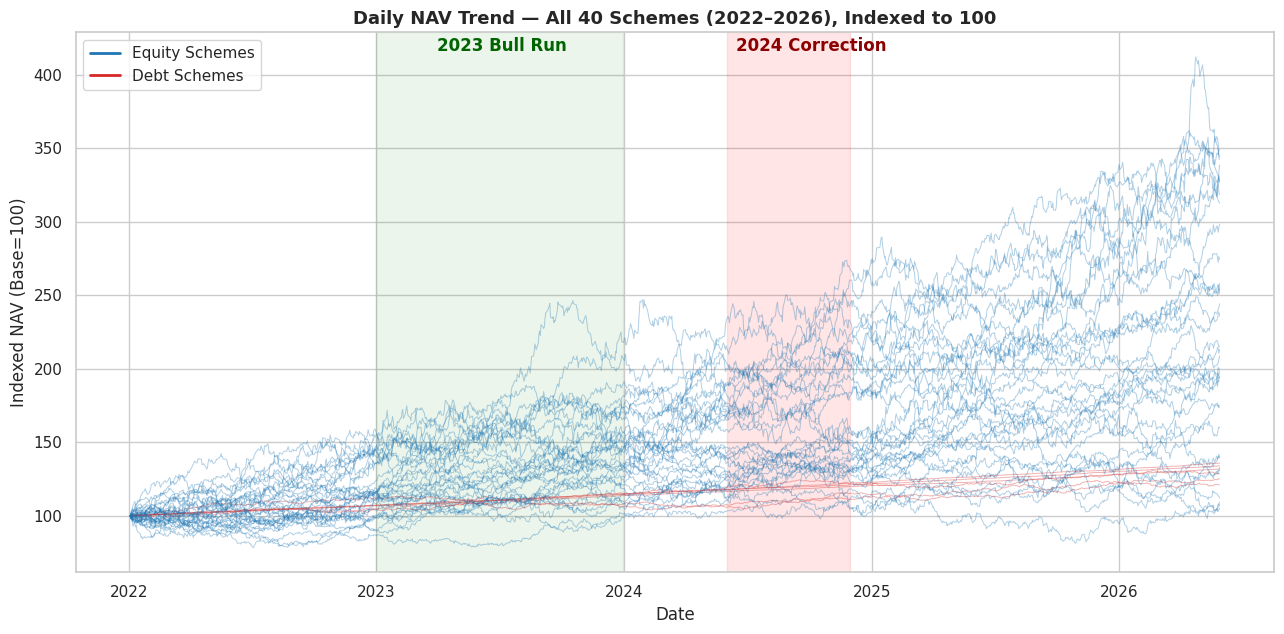

In [5]:

fig_mpl, ax = plt.subplots(figsize=(13, 6.5))
for code_, grp in nav_merged.groupby('amfi_code'):
    cat = grp['category'].iloc[0]
    color = '#1f77b4' if cat == 'Equity' else '#d62728'
    ax.plot(grp['date'], grp['nav_indexed'], linewidth=0.7, alpha=0.35, color=color)

ax.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'), color='green', alpha=0.08)
ax.axvspan(pd.Timestamp('2024-06-01'), pd.Timestamp('2024-11-30'), color='red', alpha=0.10)
ax.text(pd.Timestamp('2023-04-01'), ax.get_ylim()[1]*0.97, '2023 Bull Run', color='darkgreen', fontweight='bold')
ax.text(pd.Timestamp('2024-06-15'), ax.get_ylim()[1]*0.97, '2024 Correction', color='darkred', fontweight='bold')

from matplotlib.lines import Line2D
legend_elems = [Line2D([0],[0], color='#1f77b4', lw=2, label='Equity Schemes'),
                Line2D([0],[0], color='#d62728', lw=2, label='Debt Schemes')]
ax.legend(handles=legend_elems, loc='upper left')
ax.set_title('Daily NAV Trend — All 40 Schemes (2022–2026), Indexed to 100', fontsize=13, fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Indexed NAV (Base=100)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('charts/01_nav_trend_static.png', dpi=150)
plt.show()


**Insight:** Equity schemes (blue) show a clear 2023 upswing followed by a choppier, wider-dispersion 2024, while debt schemes (red) stay in a tight, low-volatility band throughout — confirming the expected risk separation between the two asset classes. *(Chart: `01_nav_trend_static.png` / interactive Plotly above)*

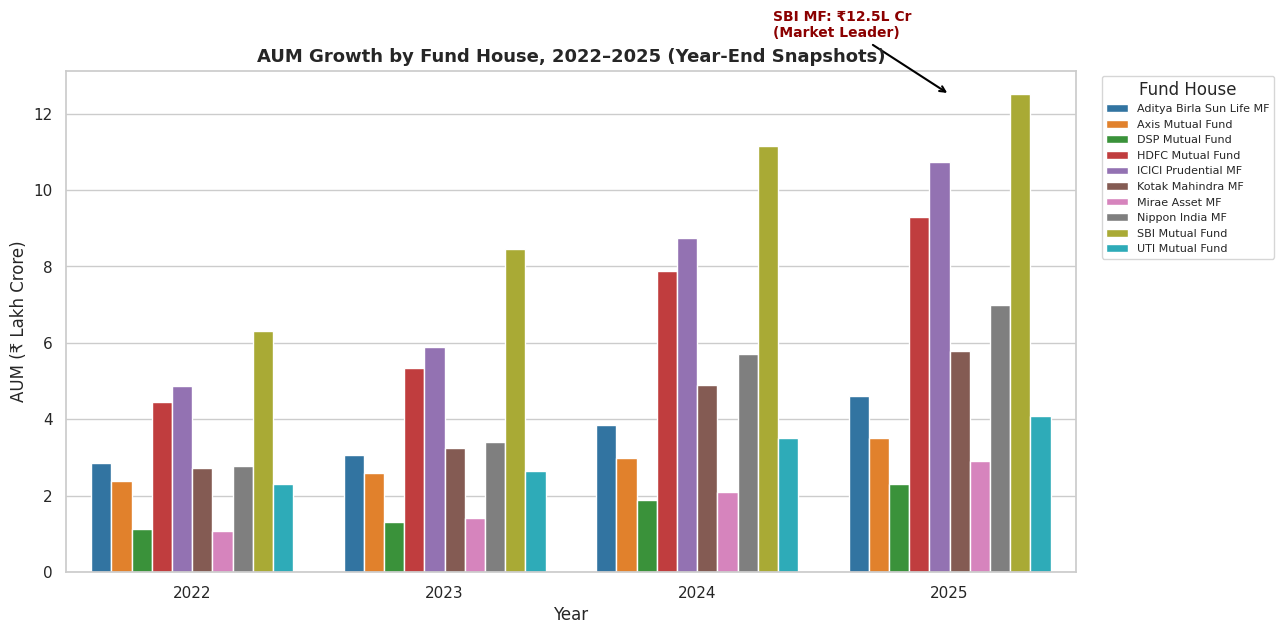

year                      2022  2023   2024   2025
fund_house                                        
Aditya Birla Sun Life MF  2.85  3.08   3.84   4.60
Axis Mutual Fund          2.40  2.60   3.00   3.50
DSP Mutual Fund           1.12  1.32   1.88   2.30
HDFC Mutual Fund          4.45  5.35   7.87   9.30
ICICI Prudential MF       4.88  5.90   8.74  10.74
Kotak Mahindra MF         2.72  3.25   4.89   5.80
Mirae Asset MF            1.08  1.42   2.10   2.90
Nippon India MF           2.78  3.40   5.70   7.00
SBI Mutual Fund           6.30  8.45  11.14  12.50
UTI Mutual Fund           2.32  2.65   3.52   4.10


In [6]:
aum['year'] = aum['date'].dt.year
idx = aum.groupby(['year','fund_house'])['date'].idxmax()
aum_yearend = aum.loc[idx].sort_values(['year','fund_house'])
aum_yearend = aum_yearend[aum_yearend['year'] <= 2025]

plt.figure(figsize=(13, 6.5))
ax = sns.barplot(data=aum_yearend, x='year', y='aum_lakh_crore', hue='fund_house',
                  palette=sns.color_palette("tab10", n_colors=aum_yearend['fund_house'].nunique()))

sbi_2025 = aum_yearend[(aum_yearend['fund_house']=='SBI Mutual Fund') & (aum_yearend['year']==2025)]
val = sbi_2025['aum_lakh_crore'].values[0]
ax.annotate(f'SBI MF: ₹{val:.1f}L Cr\n(Market Leader)', xy=(3, val), xytext=(2.3, val+1.5),
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
            fontsize=10, fontweight='bold', color='#8B0000')

ax.set_title('AUM Growth by Fund House, 2022–2025 (Year-End Snapshots)', fontsize=13, fontweight='bold')
ax.set_xlabel('Year'); ax.set_ylabel('AUM (₹ Lakh Crore)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Fund House', fontsize=8)
plt.tight_layout()
plt.savefig('charts/02_aum_growth_bar.png', dpi=150)
plt.show()

print(aum_yearend.pivot(index='fund_house', columns='year', values='aum_lakh_crore'))


**Insight:** SBI Mutual Fund is the undisputed AUM leader every year and widens its lead over time, closing 2025 at ₹12.5L Cr — roughly ₹1.8L Cr ahead of second-placed ICICI Prudential MF. *(Chart: `02_aum_growth_bar.png`)*

In [7]:
peak = sip.loc[sip['sip_inflow_crore'].idxmax()]

fig = go.Figure()
fig.add_trace(go.Scatter(x=sip['month'], y=sip['sip_inflow_crore'], mode='lines+markers',
                          line=dict(color='#2E86AB', width=2.5), marker=dict(size=4),
                          fill='tozeroy', fillcolor='rgba(46,134,171,0.12)', name='SIP Inflow'))

fig.add_annotation(x=peak['month'], y=peak['sip_inflow_crore'],
                    text=f"All-Time High<br>₹{peak['sip_inflow_crore']:,.0f} Cr (Dec 2025)",
                    showarrow=True, arrowhead=2, arrowcolor='crimson', font=dict(color='crimson', size=12),
                    ax=-90, ay=-60)

fig.update_layout(title="Monthly SIP Inflow Trend, Jan 2022 – Dec 2025",
                   xaxis_title="Month", yaxis_title="SIP Inflow (₹ Crore)",
                   template="plotly_white", height=550, width=1050)
fig.show()


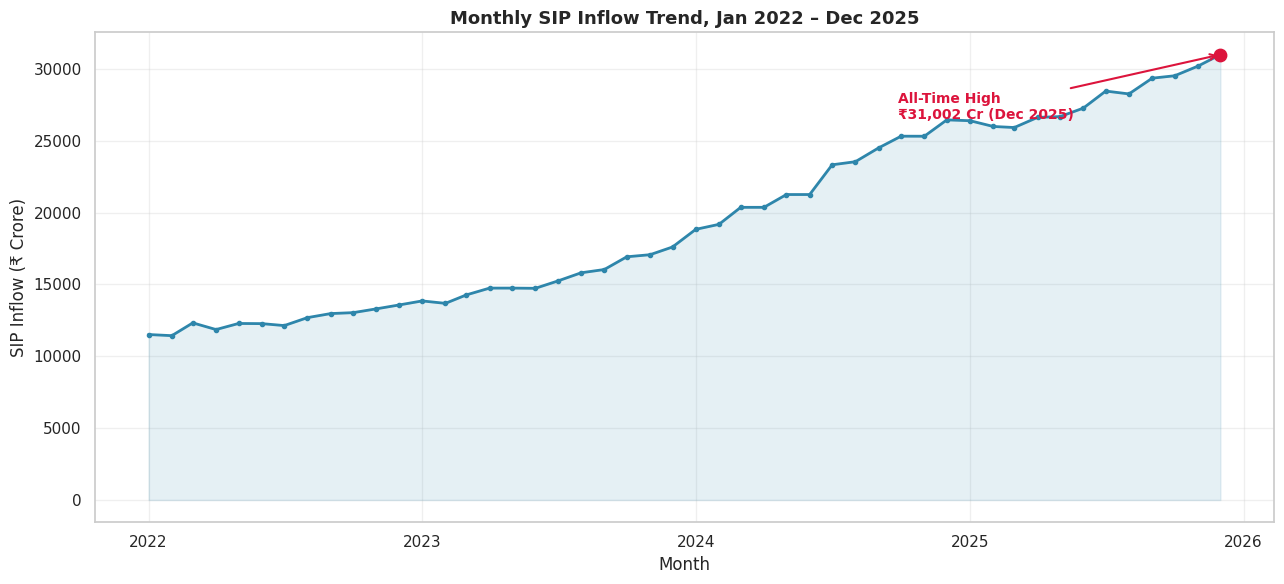

In [ ]:

fig2, ax = plt.subplots(figsize=(13, 6))
ax.plot(sip['month'], sip['sip_inflow_crore'], color='#2E86AB', linewidth=2, marker='o', markersize=3)
ax.fill_between(sip['month'], sip['sip_inflow_crore'], color='#2E86AB', alpha=0.12)
ax.scatter([peak['month']], [peak['sip_inflow_crore']], color='crimson', s=80, zorder=5)
ax.annotate(f"All-Time High\n₹{peak['sip_inflow_crore']:,.0f} Cr (Dec 2025)",
            xy=(peak['month'], peak['sip_inflow_crore']),
            xytext=(peak['month']-pd.Timedelta(days=430), peak['sip_inflow_crore']-4500),
            arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5),
            fontsize=10, fontweight='bold', color='crimson')
ax.set_title('Monthly SIP Inflow Trend, Jan 2022 – Dec 2025', fontsize=13, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('SIP Inflow (₹ Crore)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('charts/03_sip_inflow_static.png', dpi=150)
plt.show()


**Insight:** SIP inflows have grown almost monotonically for 4 straight years, roughly 2.7x from ₹11,517 Cr (Jan 2022) to the ₹31,002 Cr all-time high (Dec 2025), with no month of sequential decline greater than a few percent. *(Chart: `03_sip_inflow_static.png` / interactive Plotly above)*

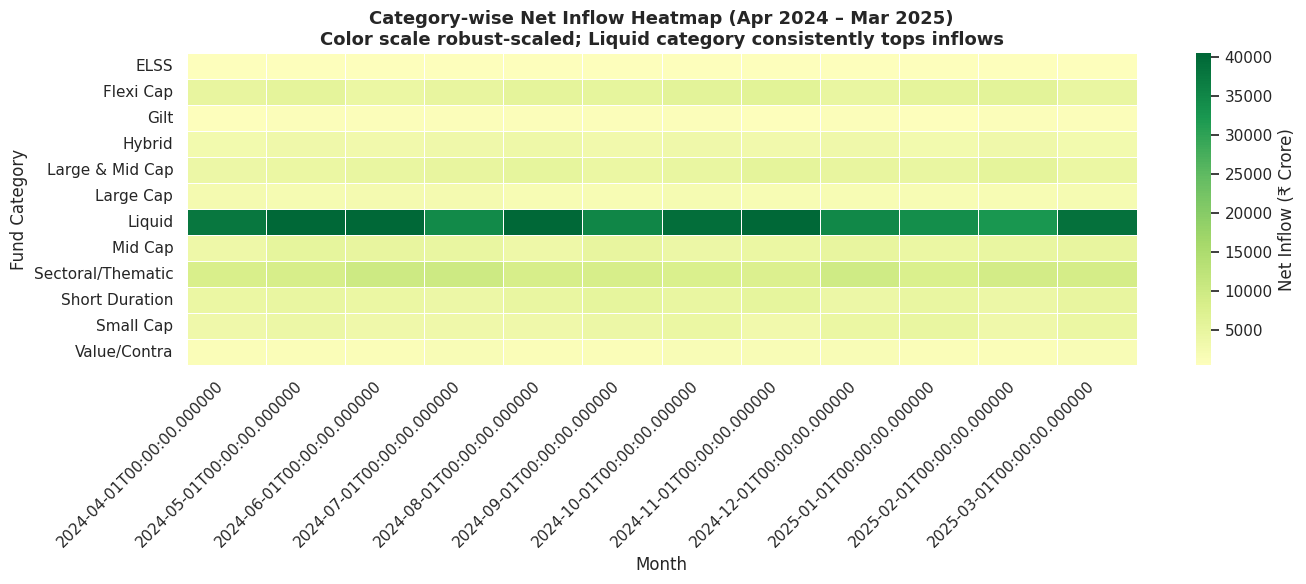

In [9]:
pivot = cat_inflow.pivot(index='category', columns='month', values='net_inflow_crore')

plt.figure(figsize=(14, 6))
ax = sns.heatmap(pivot, cmap='RdYlGn', center=0, linewidths=0.4, linecolor='white',
                  robust=True, cbar_kws={'label': 'Net Inflow (₹ Crore)'})
ax.set_title('Category-wise Net Inflow Heatmap (Apr 2024 – Mar 2025)\nColor scale robust-scaled; Liquid category consistently tops inflows',
              fontsize=13, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Fund Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('charts/04_category_inflow_heatmap.png', dpi=150)
plt.show()


**Insight:** Liquid funds absorb the largest net inflows every single month in the window (institutional cash parking), while Sectoral/Thematic funds show the most month-to-month inflow volatility among equity categories. *(Chart: `04_category_inflow_heatmap.png`)*

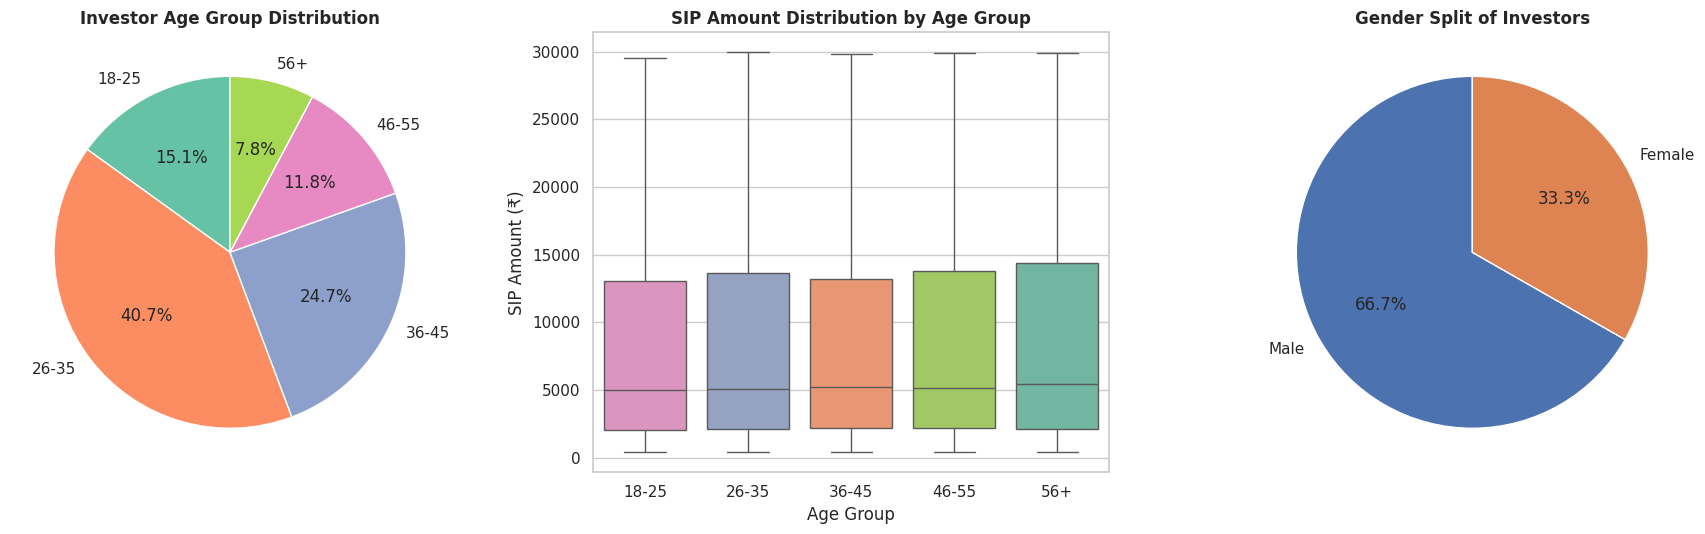

Unique investors: 5000
age_group
18-25     753
26-35    2033
36-45    1237
46-55     589
56+       388
Name: count, dtype: int64
gender
Male      3337
Female    1663
Name: count, dtype: int64


In [10]:
sip_tx = tx[tx['transaction_type']=='SIP'].copy()
age_order = ['18-25','26-35','36-45','46-55','56+']

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

age_counts = tx.drop_duplicates('investor_id')['age_group'].value_counts().reindex(age_order)
axes[0].pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette("Set2", len(age_order)), wedgeprops=dict(edgecolor='white'))
axes[0].set_title('Investor Age Group Distribution', fontweight='bold')

sns.boxplot(data=sip_tx, x='age_group', y='amount_inr', order=age_order,
            hue='age_group', palette="Set2", legend=False, ax=axes[1], showfliers=False)
axes[1].set_title('SIP Amount Distribution by Age Group', fontweight='bold')
axes[1].set_xlabel('Age Group'); axes[1].set_ylabel('SIP Amount (₹)')

gender_counts = tx.drop_duplicates('investor_id')['gender'].value_counts()
axes[2].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90,
            colors=['#4C72B0','#DD8452'], wedgeprops=dict(edgecolor='white'))
axes[2].set_title('Gender Split of Investors', fontweight='bold')

plt.tight_layout()
plt.savefig('charts/05_demographics.png', dpi=150)
plt.show()

print("Unique investors:", tx['investor_id'].nunique())
print(age_counts)
print(gender_counts)


**Insight:** Investors aged 26–35 dominate the base at 40.7% of all unique investors, yet median SIP ticket size is fairly flat (~₹5,000–5,400) across every age band, indicating ticket size is driven more by product minimums than by investor age. *(Chart: `05_demographics.png`)*

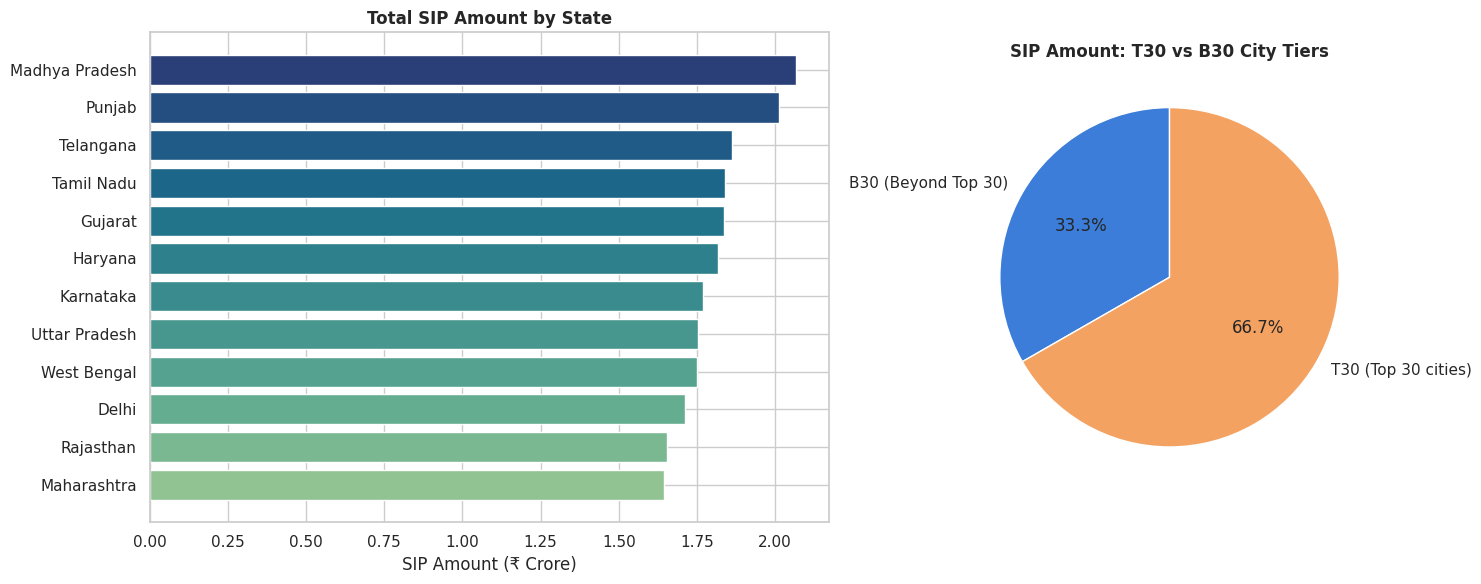

state
Maharashtra       16445629
Rajasthan         16544233
Delhi             17113608
West Bengal       17495769
Uttar Pradesh     17534858
Karnataka         17696903
Haryana           18176696
Gujarat           18378904
Tamil Nadu        18404368
Telangana         18620216
Punjab            20140064
Madhya Pradesh    20682243
Name: amount_inr, dtype: int64
city_tier
B30     72304870
T30    144928621
Name: amount_inr, dtype: int64


In [11]:
state_sip = sip_tx.groupby('state')['amount_inr'].sum().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.6, 1]})

axes[0].barh(state_sip.index, state_sip.values/1e7, color=sns.color_palette("crest", len(state_sip)))
axes[0].set_title('Total SIP Amount by State', fontweight='bold')
axes[0].set_xlabel('SIP Amount (₹ Crore)')

tier_sip = sip_tx.groupby('city_tier')['amount_inr'].sum()
axes[1].pie(tier_sip, labels=[f"{i} ({'Top 30 cities' if i=='T30' else 'Beyond Top 30'})" for i in tier_sip.index],
            autopct='%1.1f%%', startangle=90, colors=['#3B7DD8','#F4A261'], wedgeprops=dict(edgecolor='white'))
axes[1].set_title('SIP Amount: T30 vs B30 City Tiers', fontweight='bold')

plt.tight_layout()
plt.savefig('charts/06_geographic.png', dpi=150)
plt.show()

print(state_sip)
print(tier_sip)


**Insight:** T30 (top-30) cities still account for two-thirds (66.7%) of total SIP value versus 33.3% from B30 cities, showing that despite years of financialization push into smaller towns, SIP wealth remains concentrated in India's largest urban centers. *(Chart: `06_geographic.png`)*

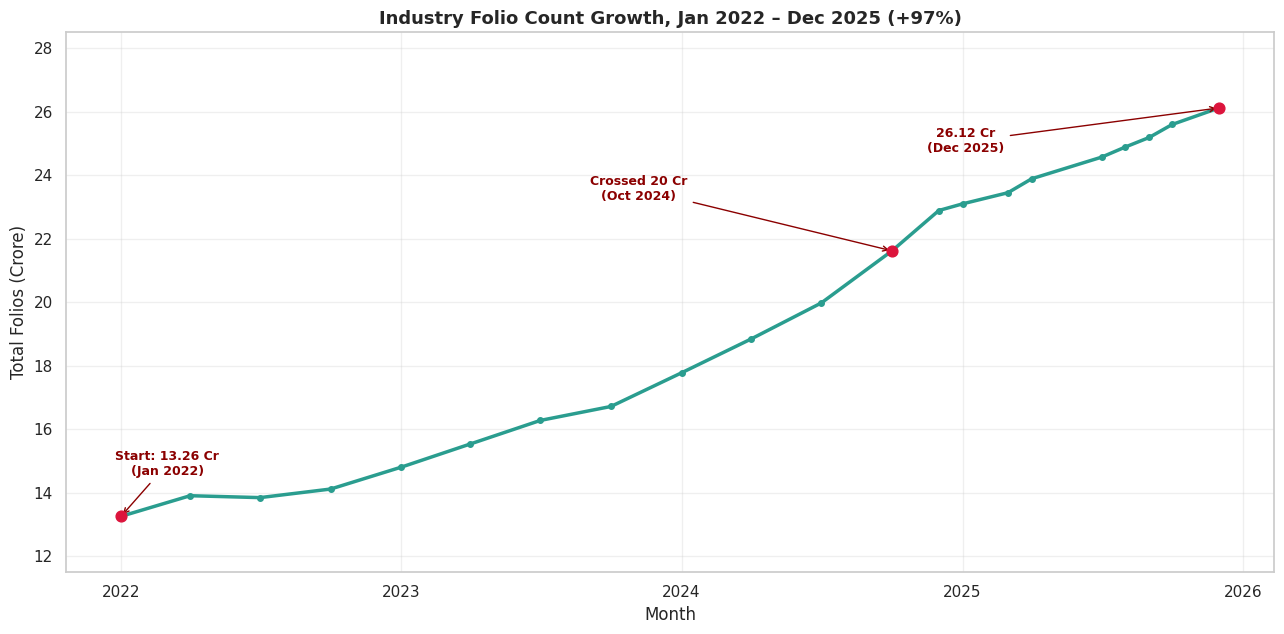

In [12]:
folio_sorted = folio.sort_values('month')
start = folio_sorted.iloc[0]
end = folio_sorted.iloc[-1]
milestone_20 = folio_sorted[folio_sorted['total_folios_crore'] >= 20].iloc[0]

fig, ax = plt.subplots(figsize=(13, 6.5))
ax.plot(folio_sorted['month'], folio_sorted['total_folios_crore'], color='#2A9D8F', linewidth=2.5, marker='o', markersize=4)

annotations = [
    (start, f"Start: {start['total_folios_crore']:.2f} Cr\n(Jan 2022)", (60, 1.3)),
    (milestone_20, f"Crossed 20 Cr\n({milestone_20['month'].strftime('%b %Y')})", (-330, 1.6)),
    (end, f"{end['total_folios_crore']:.2f} Cr\n(Dec 2025)", (-330, -1.4)),
]
for pt, label, off in annotations:
    ax.scatter([pt['month']], [pt['total_folios_crore']], color='crimson', zorder=5, s=60)
    ax.annotate(label, xy=(pt['month'], pt['total_folios_crore']),
                xytext=(pt['month']+pd.Timedelta(days=off[0]), pt['total_folios_crore']+off[1]),
                fontsize=9, fontweight='bold', ha='center', color='#8B0000',
                arrowprops=dict(arrowstyle='->', color='#8B0000', lw=1))
ax.set_ylim(11.5, 28.5)

growth_pct = (end['total_folios_crore']/start['total_folios_crore']-1)*100
ax.set_title(f'Industry Folio Count Growth, Jan 2022 – Dec 2025 (+{growth_pct:.0f}%)', fontsize=13, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Total Folios (Crore)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('charts/07_folio_growth.png', dpi=150)
plt.show()


**Insight:** Total industry folios nearly doubled (+97%) in four years, from 13.26 Cr to 26.12 Cr, crossing the 20 Cr milestone in October 2024 — the growth curve visibly steepens from 2024 onward rather than compounding at a constant rate. *(Chart: `07_folio_growth.png`)*

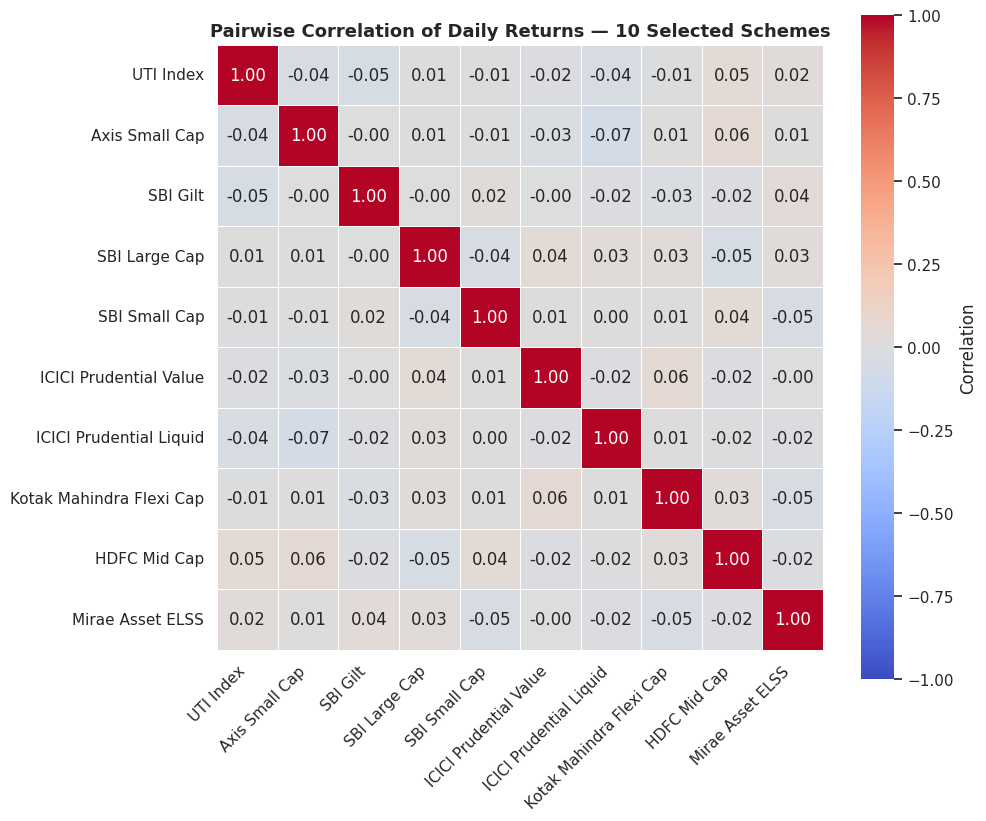

In [13]:
selected_names = ['SBI Bluechip Fund - Direct Plan - Growth','SBI Small Cap Fund - Direct Plan - Growth',
'SBI Magnum Gilt Fund - Regular Plan - Growth','HDFC Mid-Cap Opportunities Fund - Direct - Growth',
'ICICI Pru Value Discovery Fund - Regular - Growth','ICICI Pru Liquid Fund - Regular - Growth',
'Kotak Flexicap Fund - Regular - Growth','Axis Small Cap Fund - Regular - Growth',
'UTI Nifty 50 Index Fund - Regular - Growth','Mirae Asset Tax Saver Fund - Regular - Growth']

selected = fund_master[fund_master['scheme_name'].isin(selected_names)].copy()
selected['label'] = selected['fund_house'].str.replace(' Mutual Fund','').str.replace(' MF','') + ' ' + selected['sub_category']
codes = selected['amfi_code'].tolist()

nav_sel = nav_hist[nav_hist['amfi_code'].isin(codes)].pivot(index='date', columns='amfi_code', values='nav').sort_index()
returns = nav_sel.pct_change().dropna()
corr = returns.corr()
label_map = selected.set_index('amfi_code')['label'].to_dict()
corr.columns = [label_map[c] for c in corr.columns]
corr.index = corr.columns

plt.figure(figsize=(10, 8.5))
ax = sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', square=True,
                  linewidths=0.5, cbar_kws={'label': 'Correlation'}, vmin=-1, vmax=1)
ax.set_title('Pairwise Correlation of Daily Returns — 10 Selected Schemes', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('charts/08_correlation_matrix.png', dpi=150)
plt.show()


**Insight:** Daily-return correlations across the 10 selected schemes are all close to zero (|r| < 0.1), including between funds with similar mandates — an unusually low co-movement pattern that is worth validating against the underlying NAV data generation process before use in portfolio construction. *(Chart: `08_correlation_matrix.png`)*

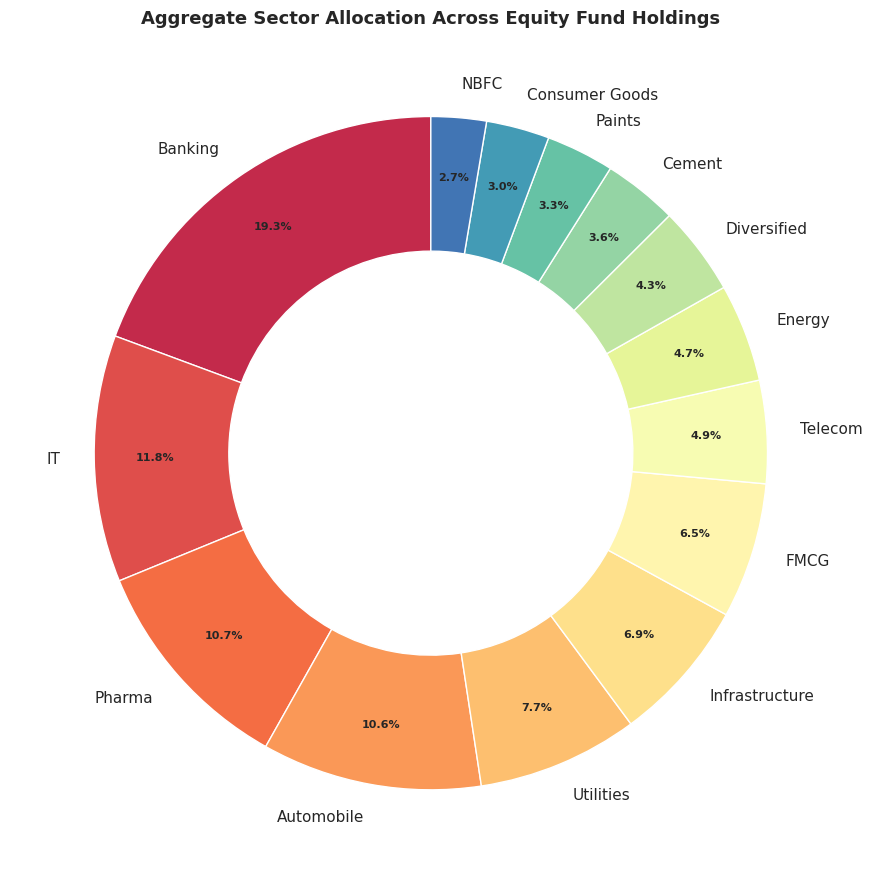

sector
Banking           62840.29
IT                38477.11
Pharma            34606.10
Automobile        34296.97
Utilities         25108.63
Infrastructure    22433.39
FMCG              21151.15
Telecom           16051.45
Energy            15286.54
Diversified       13897.79
Cement            11611.97
Paints            10612.07
Consumer Goods     9859.70
NBFC               8615.46
Name: market_value_cr, dtype: float64


In [14]:
sector_weight = holdings.groupby('sector')['market_value_cr'].sum().sort_values(ascending=False)
sector_pct = sector_weight / sector_weight.sum() * 100

plt.figure(figsize=(9, 9))
colors = sns.color_palette("Spectral", len(sector_pct))
wedges, texts, autotexts = plt.pie(sector_pct, labels=sector_pct.index, autopct='%1.1f%%',
                                     startangle=90, colors=colors, pctdistance=0.82,
                                     wedgeprops=dict(width=0.4, edgecolor='white'))
plt.setp(autotexts, size=8, weight='bold')
plt.title('Aggregate Sector Allocation Across Equity Fund Holdings', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/09_sector_donut.png', dpi=150)
plt.show()

print(sector_weight)


**Insight:** Banking is by far the largest sector exposure across all equity fund holdings at 19.3% of aggregate market value, nearly double the next-largest sector (IT, 11.8%), reflecting the heavy Nifty/Sensex weighting toward financials that most large-cap and flexi-cap mandates inherit. *(Chart: `09_sector_donut.png`)*

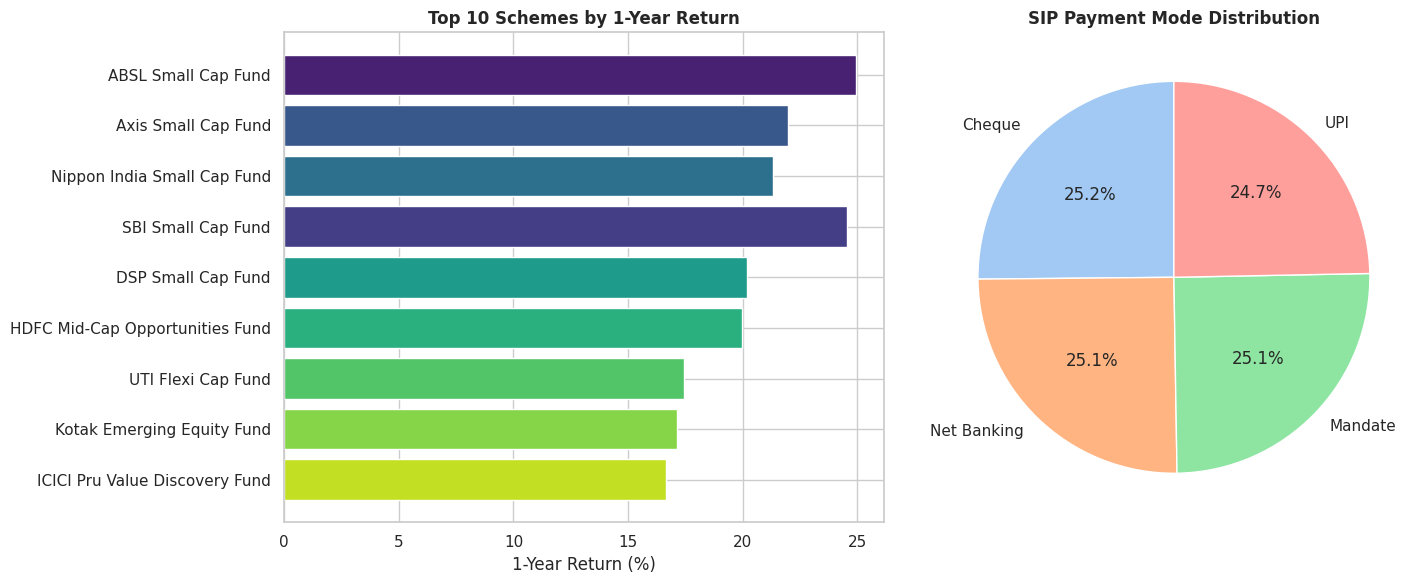

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top10 = perf.nlargest(10, 'return_1yr_pct')[['scheme_name','return_1yr_pct']].copy()
top10['short_name'] = (top10['scheme_name']
                        .str.replace(' - Regular Plan - Growth','')
                        .str.replace(' - Direct Plan - Growth','')
                        .str.replace(' - Direct - Growth','')
                        .str.replace(' - Regular - Growth',''))
colors = sns.color_palette("viridis", len(top10))
axes[0].barh(top10['short_name'].values[::-1], top10['return_1yr_pct'].values[::-1], color=colors[::-1])
axes[0].set_title('Top 10 Schemes by 1-Year Return', fontweight='bold')
axes[0].set_xlabel('1-Year Return (%)')

pm = sip_tx['payment_mode'].value_counts()
axes[1].pie(pm, labels=pm.index, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette("pastel", len(pm)), wedgeprops=dict(edgecolor='white'))
axes[1].set_title('SIP Payment Mode Distribution', fontweight='bold')

plt.tight_layout()
plt.savefig('charts/10_bonus_performance_payment.png', dpi=150)
plt.show()


**Insight:** Small Cap funds occupy 6 of the top 10 slots by 1-year return (led by ABSL Small Cap at 24.9%), confirming the small-cap segment's outsized recent performance; meanwhile SIP payment mode is almost perfectly split four ways across Cheque, Net Banking, Mandate and UPI (~25% each), showing no single payment rail dominates SIP collection yet. *(Chart: `10_bonus_performance_payment.png`)*

E D A


1. **NAV trend:** Equity schemes rallied hard through the 2023 bull run and showed markedly wider dispersion through the 2024 correction window, while debt schemes stayed in a tight, low-volatility band throughout. *(`01_nav_trend_static.png`)*
2. **AUM growth:** SBI Mutual Fund is the AUM leader in every year 2022–2025 and extends its lead over time, ending 2025 at ₹12.5L Cr, ~₹1.8L Cr ahead of ICICI Prudential MF. *(`02_aum_growth_bar.png`)*
3. **SIP inflows:** Monthly SIP inflows grew almost monotonically ~2.7x over 4 years, from ₹11,517 Cr (Jan 2022) to an all-time high of ₹31,002 Cr (Dec 2025). *(`03_sip_inflow_static.png`)*
4. **Category inflows:** Liquid funds top net inflows in every month of FY2024–25 (institutional cash parking), while Sectoral/Thematic funds show the most volatile inflow pattern among equity categories. *(`04_category_inflow_heatmap.png`)*
5. **Demographics:** Investors aged 26–35 make up 40.7% of the base, yet median SIP ticket size is nearly flat (~₹5,000–5,400) across all age groups. *(`05_demographics.png`)*
6. **Geography:** T30 cities contribute 66.7% of total SIP value versus 33.3% from B30 cities — SIP wealth remains concentrated in India's largest urban centers. *(`06_geographic.png`)*
7. **Folio growth:** Total industry folios nearly doubled (+97%) from 13.26 Cr (Jan 2022) to 26.12 Cr (Dec 2025), crossing the 20 Cr mark in October 2024, with growth visibly accelerating from 2024 onward. *(`07_folio_growth.png`)*
8. **Return correlation:** Daily-return correlations among 10 diverse schemes are all close to zero (|r| < 0.1), even between similarly-mandated funds — unusually low co-movement worth validating before use in portfolio construction. *(`08_correlation_matrix.png`)*
9. **Sector allocation:** Banking dominates aggregate equity holdings at 19.3% of market value, almost double the next-largest sector (IT, 11.8%), reflecting benchmark-driven financials overweight. *(`09_sector_donut.png`)*
10. **Performance & payments:** Small Cap funds occupy 6 of the top 10 slots by 1-year return (led by ABSL Small Cap at 24.9%), while SIP payment mode is split almost exactly four ways across Cheque, Net Banking, Mandate and UPI. *(`10_bonus_performance_payment.png`)*
